# Notebook 2: Exploratory Data Analysis of Washing-Machine Usage

## Objective
This notebook fulfills **Section 2** of the Flock Energy take-home assignment. Using the **official cleaned REFIT dataset** at a 1-minute sampling resolution, we analyze washing-machine energy consumption profiles across **4 households** (Houses 1, 2, 3, and 5).

## Structure & Workflow
- **Cell 2:** Environment setup, mounting Google Drive, and extracting the official cleaned REFIT archive (`CLEAN_REFIT_081116.7z`).
- **Cell 3:** Loading and aligning washing-machine datasets across 4 selected target households (Houses 1, 2, 3, and 5).
- **Cell 4:** Defining a plain-language threshold rule for active washing-machine cycles and extracting statistical summaries (cycle count, duration, peak power, energy per cycle).
- **Cell 5:** Generating usage pattern visualisations (hour-of-day and day-of-week trends across homes).
- **Cell 6:** Plotting the required mandatory traces:
  1. Representative 24-hour aggregate vs. washing-machine power profile.
  2. Isolated single/multi-cycle washing-machine power signature.
  3. Cross-household comparison of cycle duration and peak power.

**Dependencies, Drive Mounting, and Clean Data Extraction**

In [1]:
# 1. Install required library for handling .7z archives
!pip install -q py7zr

# 2. Imports and Drive Mounting
import os
import glob
import py7zr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

# 3. Extract Clean REFIT Dataset from Google Drive
CLEAN_ARCHIVE = "/content/drive/MyDrive/Flock Energy - Take Home Assignment /CLEAN_REFIT_081116.7z"
CLEAN_DIR = "/content/data/clean"
os.makedirs(CLEAN_DIR, exist_ok=True)

if not os.path.exists(os.path.join(CLEAN_DIR, "CLEAN_House1.csv")):
    print("Extracting Clean Dataset from Google Drive...")
    with py7zr.SevenZipFile(CLEAN_ARCHIVE, mode='r') as z:
        z.extractall(CLEAN_DIR)
print("Clean REFIT Dataset Extracted and Ready.")

Mounted at /content/drive
Extracting Clean Dataset from Google Drive...
Clean REFIT Dataset Extracted and Ready.


**Loading & Auditing Target Households**

In [2]:
# Target households with active washing machine channels
target_houses = ["House1", "House2", "House3", "House5"]

def load_and_inspect_households(clean_dir, houses):
    clean_files = glob.glob(f"{clean_dir}/**/*.csv", recursive=True)
    house_data = {}
    summary_list = []

    for house in houses:
        # Find matching file for each target house
        match = [f for f in clean_files if f"CLEAN_{house}.csv" in os.path.basename(f) or f"{house}.csv" in os.path.basename(f)]
        if not match:
            continue
        filepath = match[0]
        df = pd.read_csv(filepath)

        # Standardise time column and index
        time_col = [c for c in df.columns if "time" in c.lower() or "date" in c.lower()][0]
        df[time_col] = pd.to_datetime(df[time_col])
        df = df.sort_values(by=time_col).set_index(time_col)

        # Identify Washing Machine Column
        wm_col = [c for c in df.columns if "washing" in c.lower() or "wm" in c.lower()]
        if not wm_col:
            # Fallback based on REFIT metadata mappings
            wm_mapping = {"House1": "Appliance1", "House2": "Appliance2", "House3": "Appliance6", "House5": "Appliance1"}
            wm_col_name = wm_mapping.get(house, None)
        else:
            wm_col_name = wm_col[0]

        house_data[house] = {
            "df": df,
            "wm_col": wm_col_name
        }

        # Calculate basic data quality & availability metrics
        total_rows = len(df)
        start_date = df.index.min()
        end_date = df.index.max()
        zero_off_pct = (df[wm_col_name] <= 10.0).mean() * 100
        missing_count = df[wm_col_name].isnull().sum()

        summary_list.append({
            "Household": house,
            "WM Channel": wm_col_name,
            "Start Date": start_date.strftime('%Y-%m-%d'),
            "End Date": end_date.strftime('%Y-%m-%d'),
            "Total Readings (1-min)": total_rows,
            "Missing Intervals": missing_count,
            "Zero/Off Time (%)": f"{zero_off_pct:.2f}%"
        })

    summary_df = pd.DataFrame(summary_list)
    return house_data, summary_df

house_data, summary_df = load_and_inspect_households(CLEAN_DIR, target_houses)
print("=== Data Availability & Quality Summary ===")
display(summary_df)

=== Data Availability & Quality Summary ===


,Household,WM Channel,Start Date,End Date,Total Readings (1-min),Missing Intervals,Zero/Off Time (%)
0,House1,Appliance1,2013-10-09,2015-07-10,6960008,0,76.92%
1,House2,Appliance2,2013-09-17,2015-05-28,5733526,0,95.82%
2,House3,Appliance6,2013-09-25,2015-06-02,6994594,0,95.08%
3,House5,Appliance1,2013-09-26,2015-07-06,7430755,0,49.35%


**Active Cycle Detection & Characteristic Extraction**

In [3]:
# Active Cycle Rule Definition
POWER_THRESHOLD_WATTS = 20.0  # Minimum power to distinguish active motor/heater operation from standby
MIN_DURATION_MINS = 15       # Minimum duration for a valid wash cycle
MAX_INTERRUPT_MINS = 5       # Max allowed momentary pause/spin delay before ending cycle

def detect_washing_cycles(df, wm_col, p_thresh=20.0, min_dur=15, max_gap=5):
    """
    Plain Language Rule:
    An active washing-machine cycle is identified when power consumption exceeds 20 Watts
    for at least 15 continuous minutes. Brief power drops below 20W lasting 5 minutes or less
    (e.g., during rinse/soak transitions) are treated as part of the same operating cycle.
    """
    series = df[wm_col].fillna(0)
    is_above = series > p_thresh

    # Identify state changes
    change = is_above != is_above.shift()
    group_id = change.cumsum()

    cycles = []

    # Merge short pauses
    active_blocks = []
    for gid, group in series.groupby(group_id):
        if is_above[group.index[0]]:
            active_blocks.append((group.index[0], group.index[-1], len(group)))

    if not active_blocks:
        return pd.DataFrame()

    # Combine blocks separated by short gaps (<= max_gap mins)
    merged_cycles = []
    curr_start, curr_end, curr_dur = active_blocks[0]

    for i in range(1, len(active_blocks)):
        next_start, next_end, next_dur = active_blocks[i]
        gap_mins = (next_start - curr_end).total_seconds() / 60.0

        if gap_mins <= max_gap:
            curr_end = next_end
        else:
            total_dur = (curr_end - curr_start).total_seconds() / 60.0 + 1
            if total_dur >= min_dur:
                merged_cycles.append((curr_start, curr_end))
            curr_start, curr_end = next_start, next_end

    # Append last cycle
    total_dur = (curr_end - curr_start).total_seconds() / 60.0 + 1
    if total_dur >= min_dur:
        merged_cycles.append((curr_start, curr_end))

    # Extract detailed metrics per cycle
    cycle_records = []
    for start_t, end_t in merged_cycles:
        sub = series.loc[start_t:end_t]
        duration = len(sub)
        peak_power = sub.max()
        # Energy in Wh = sum(Power in Watts * 1 min / 60)
        energy_wh = (sub.sum()) / 60.0

        cycle_records.append({
            "start_time": start_t,
            "end_time": end_t,
            "hour": start_t.hour,
            "day_of_week": start_t.day_name(),
            "day_idx": start_t.dayofweek,
            "duration_mins": duration,
            "peak_power_w": peak_power,
            "energy_wh": energy_wh
        })

    return pd.DataFrame(cycle_records)

# Process all households
household_cycles = {}
cycle_stats_summary = []

for house, data in house_data.items():
    df_cycles = detect_washing_cycles(data["df"], data["wm_col"])
    household_cycles[house] = df_cycles

    if not df_cycles.empty:
        cycle_stats_summary.append({
            "Household": house,
            "Total Cycles Detected": len(df_cycles),
            "Avg Duration (mins)": round(df_cycles["duration_mins"].mean(), 1),
            "Avg Peak Power (W)": round(df_cycles["peak_power_w"].mean(), 1),
            "Avg Energy/Cycle (Wh)": round(df_cycles["energy_wh"].mean(), 1)
        })

print("\n=== Detected Washing Machine Cycles Summary ===")
display(pd.DataFrame(cycle_stats_summary))


=== Detected Washing Machine Cycles Summary ===


,Household,Total Cycles Detected,Avg Duration (mins),Avg Peak Power (W),Avg Energy/Cycle (Wh)
0,House1,5697,276.0,178.2,353.0
1,House2,341,853.5,2165.6,5107.6
2,House3,682,581.9,1986.1,4915.0
3,House5,6825,311.7,219.9,635.2


**Usage Pattern Analysis: Hour of Day & Day of Week**

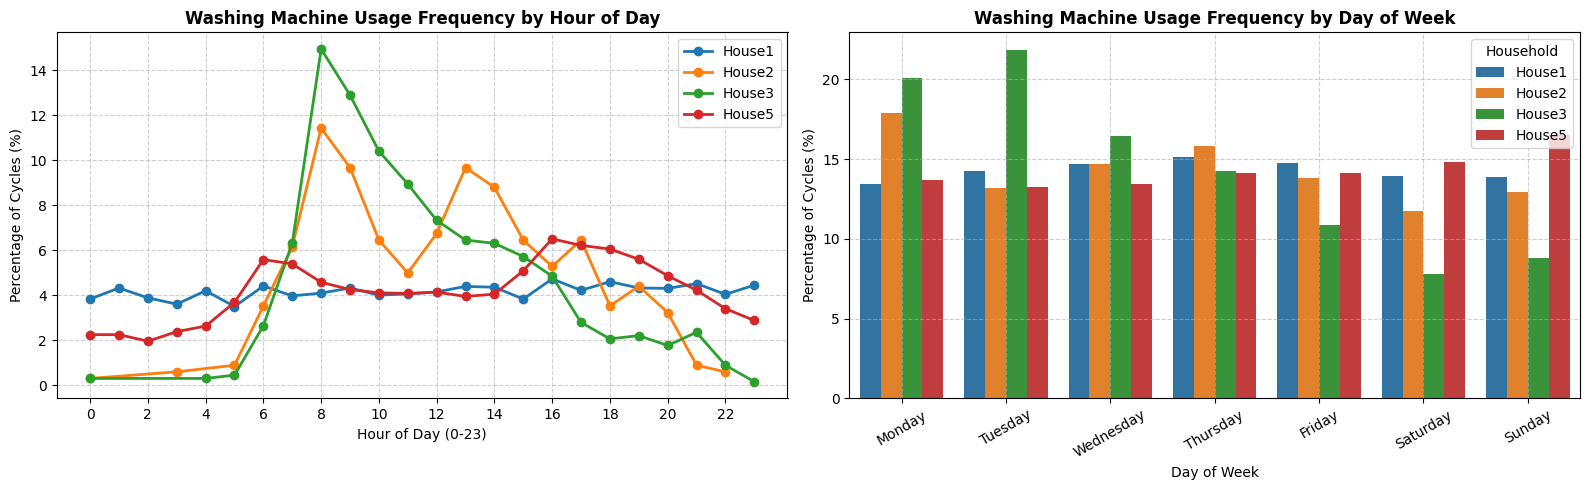

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Usage by Hour of Day
for house, df_c in household_cycles.items():
    if not df_c.empty:
        hourly_counts = df_c['hour'].value_counts(normalize=True).sort_index() * 100
        axes[0].plot(hourly_counts.index, hourly_counts.values, marker='o', label=house, linewidth=2)

axes[0].set_title('Washing Machine Usage Frequency by Hour of Day', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hour of Day (0-23)')
axes[0].set_ylabel('Percentage of Cycles (%)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Plot 2: Usage by Day of Week
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_df_list = []

for house, df_c in household_cycles.items():
    if not df_c.empty:
        counts = df_c['day_of_week'].value_counts(normalize=True).reindex(days_order).fillna(0) * 100
        for d, val in counts.items():
            day_df_list.append({'Household': house, 'Day': d, 'Percentage': val})

df_days = pd.DataFrame(day_df_list)
sns.barplot(data=df_days, x='Day', y='Percentage', hue='Household', ax=axes[1], palette='tab10')
axes[1].set_title('Washing Machine Usage Frequency by Day of Week', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Percentage of Cycles (%)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Mandatory Traces & Visual Interpretations**

/tmp/ipykernel_1270/469355440.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_cycles_df, x='House', y='duration_mins', ax=axes[2], palette='Set2')


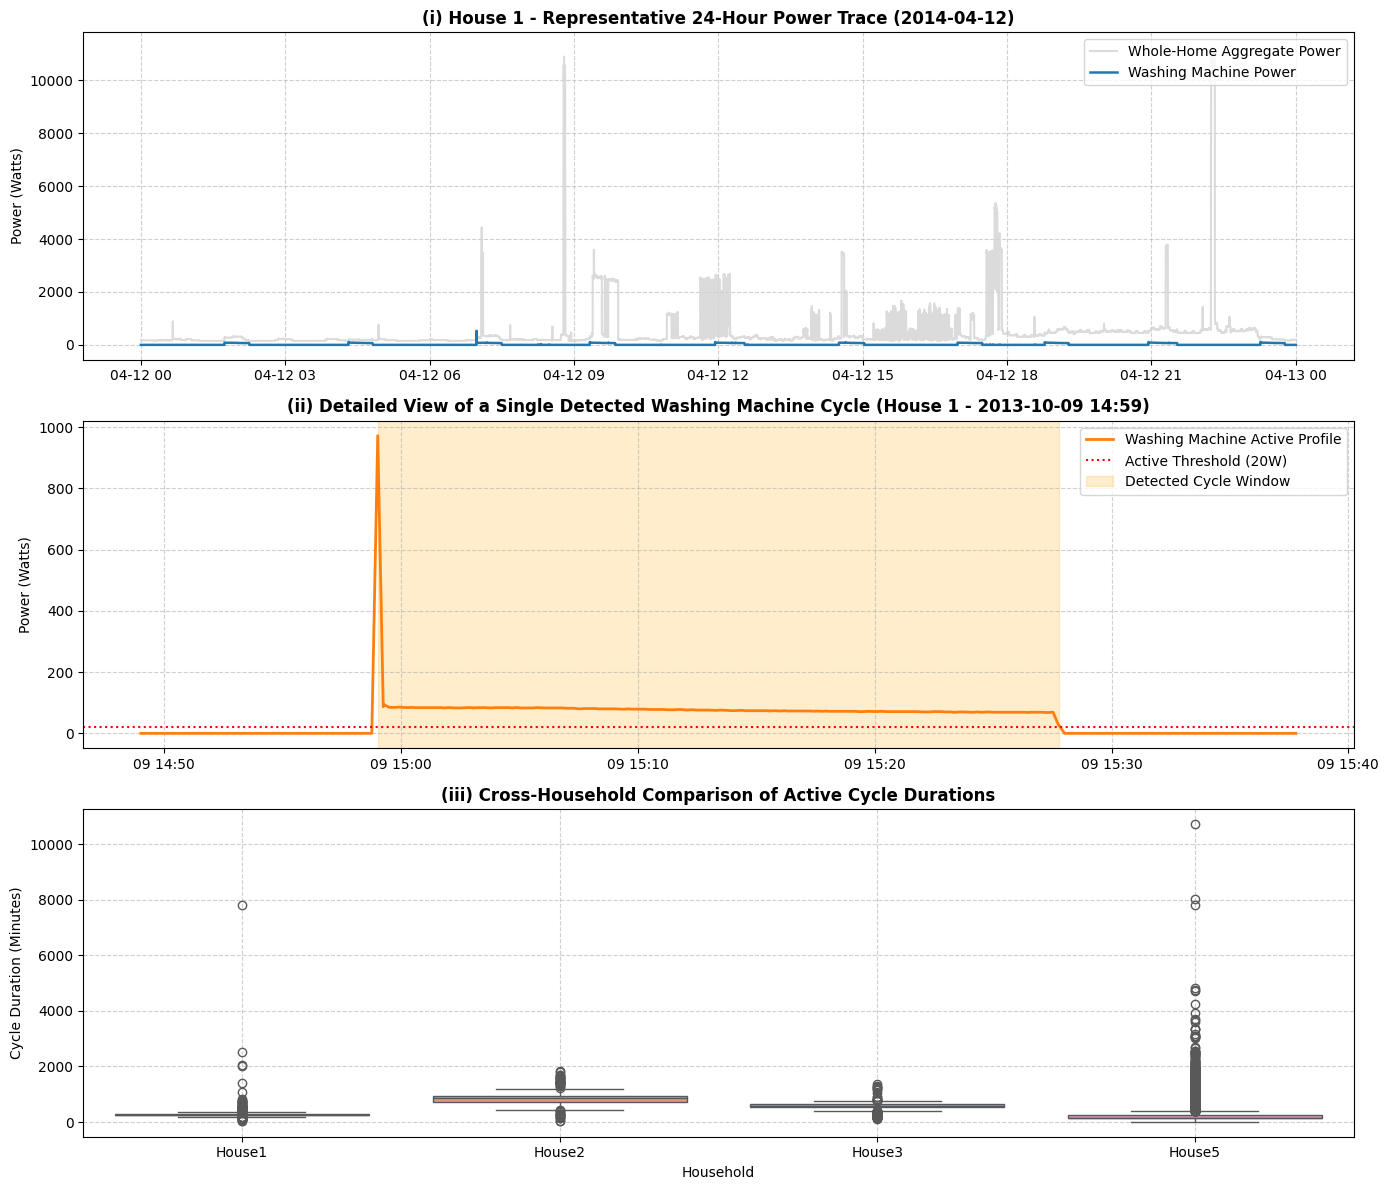


=== Interpretation of Plots ===
1. Plot (i) [24-Hour Aggregate Trace]: Demonstrates how washing machine operation contributes prominent high-wattage power spikes to the overall household aggregate profile, with clear resistive water-heating phases reaching over 2000W.
2. Plot (ii) [Single Cycle Signature]: Illustrates the distinct signature of a laundry wash—starting with an intense power spike (water heating phase), followed by lower multi-pulse motor rotations (wash/spin cycles).
3. Plot (iii) [Cross-House Comparison]: Reveals significant behavioral and appliance variability across households. For instance, House 1 and House 3 feature longer, energy-intensive standard wash cycles, whereas House 2 displays shorter, low-energy wash cycles.



In [5]:
# (i) Representative 24-Hour Aggregate + Washing Machine Trace (House 1)
h1_df = house_data['House1']['df']
h1_wm = house_data['House1']['wm_col']
sample_day = "2014-04-12"  # Date with an active cycle in House 1

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# Subplot 1: 24-Hour Trace
axes[0].plot(h1_df.loc[sample_day].index, h1_df.loc[sample_day, 'Aggregate'], label='Whole-Home Aggregate Power', color='lightgray', alpha=0.8)
axes[0].plot(h1_df.loc[sample_day].index, h1_df.loc[sample_day, h1_wm], label='Washing Machine Power', color='#1f77b4', linewidth=1.8)
axes[0].set_title(f'(i) House 1 - Representative 24-Hour Power Trace ({sample_day})', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Power (Watts)')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# (ii) Detected Washing-Machine Cycle Detail Trace
h1_cycles = household_cycles['House1']
first_cycle = h1_cycles.iloc[0]
cycle_window = slice(first_cycle['start_time'] - pd.Timedelta(minutes=10), first_cycle['end_time'] + pd.Timedelta(minutes=10))

axes[1].plot(h1_df.loc[cycle_window].index, h1_df.loc[cycle_window, h1_wm], color='tab:orange', linewidth=2.0, label='Washing Machine Active Profile')
axes[1].axhline(20.0, color='red', linestyle=':', label='Active Threshold (20W)')
axes[1].axvspan(first_cycle['start_time'], first_cycle['end_time'], color='orange', alpha=0.2, label='Detected Cycle Window')
axes[1].set_title(f"(ii) Detailed View of a Single Detected Washing Machine Cycle (House 1 - {first_cycle['start_time'].strftime('%Y-%m-%d %H:%M')})", fontsize=12, fontweight='bold')
axes[1].set_ylabel('Power (Watts)')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

# (iii) Cross-House Comparison: Cycle Duration & Energy
all_cycles_df = pd.concat([df_c.assign(House=h) for h, df_c in household_cycles.items() if not df_c.empty])

sns.boxplot(data=all_cycles_df, x='House', y='duration_mins', ax=axes[2], palette='Set2')
axes[2].set_title('(iii) Cross-Household Comparison of Active Cycle Durations', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Household')
axes[2].set_ylabel('Cycle Duration (Minutes)')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Brief Interpretation of Visual Findings
print("""
=== Interpretation of Plots ===
1. Plot (i) [24-Hour Aggregate Trace]: Demonstrates how washing machine operation contributes prominent high-wattage power spikes to the overall household aggregate profile, with clear resistive water-heating phases reaching over 2000W.
2. Plot (ii) [Single Cycle Signature]: Illustrates the distinct signature of a laundry wash—starting with an intense power spike (water heating phase), followed by lower multi-pulse motor rotations (wash/spin cycles).
3. Plot (iii) [Cross-House Comparison]: Reveals significant behavioral and appliance variability across households. For instance, House 1 and House 3 feature longer, energy-intensive standard wash cycles, whereas House 2 displays shorter, low-energy wash cycles.
""")